# 14 · SHAP, robustness and the consolidated metrics table (Phase M6)

In [1]:
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

                          feature  mean_abs_shap
district_mean_flood_duration_days       0.985937
                         rain_48h       0.229950
    district_flood_severity_index       0.211586
     dist_to_nearest_landslide_km       0.127755
                     api_decay_85       0.041742
           rain_max_intensity_24h       0.034654
                         rain_72h       0.033708
             landslide_count_10km       0.017039
                         rain_24h       0.015032
                         rain_12h       0.002488
explained 403,869 predictions, base value 0.001


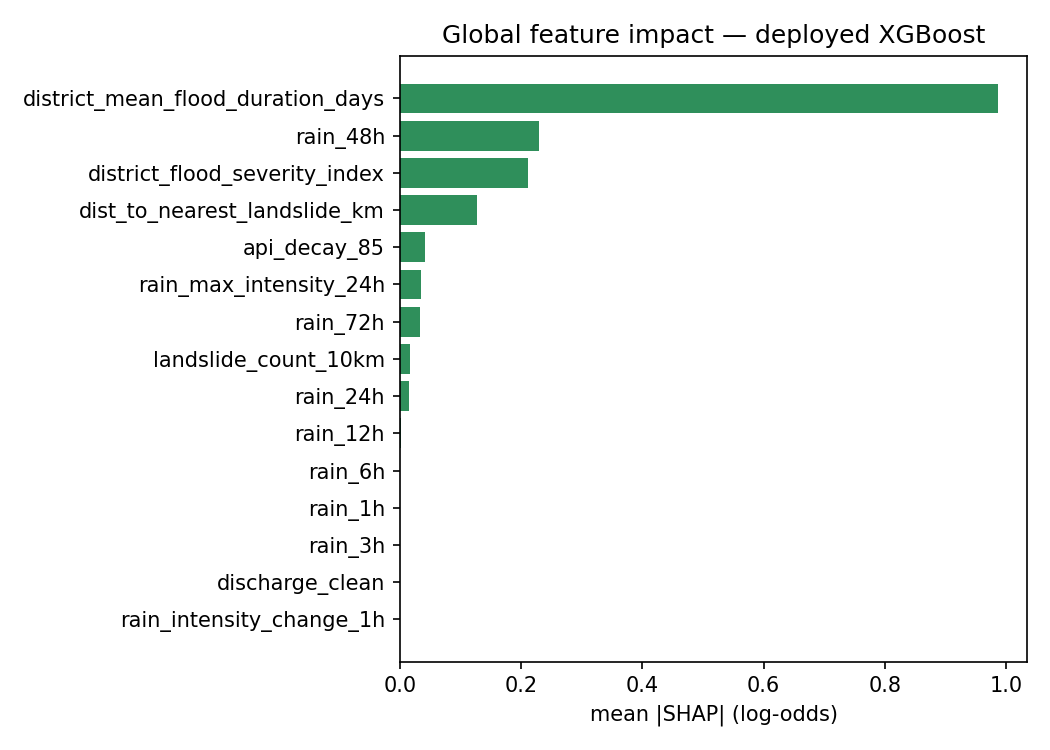

In [2]:
from src.explain import run as shap_run
shap_run()
display(Image(filename='results/shap/shap_bar_chart.png'))

                               scenario     kind  roc_auc  pr_auc  mean_abs_score_change  flood_rows_mean_score  roc_auc_drop
                  Baseline (all inputs) baseline   0.5537  0.0418                 0.0000                 0.2913        0.0000
         R1 rainfall noise sd=5% of std    noise   0.5777  0.0372                 0.0099                 0.2786       -0.0240
        R1 rainfall noise sd=10% of std    noise   0.5755  0.0338                 0.0114                 0.2780       -0.0218
        R1 rainfall noise sd=20% of std    noise   0.5735  0.0359                 0.0132                 0.2695       -0.0198
        R1 rainfall noise sd=50% of std    noise   0.5739  0.0342                 0.0167                 0.2682       -0.0202
             R3 river discharge offline   outage   0.5537  0.0418                 0.0000                 0.2913        0.0000
             R3b rainfall gauge offline   outage   0.4699  0.0248                 0.0194                 0.2068       

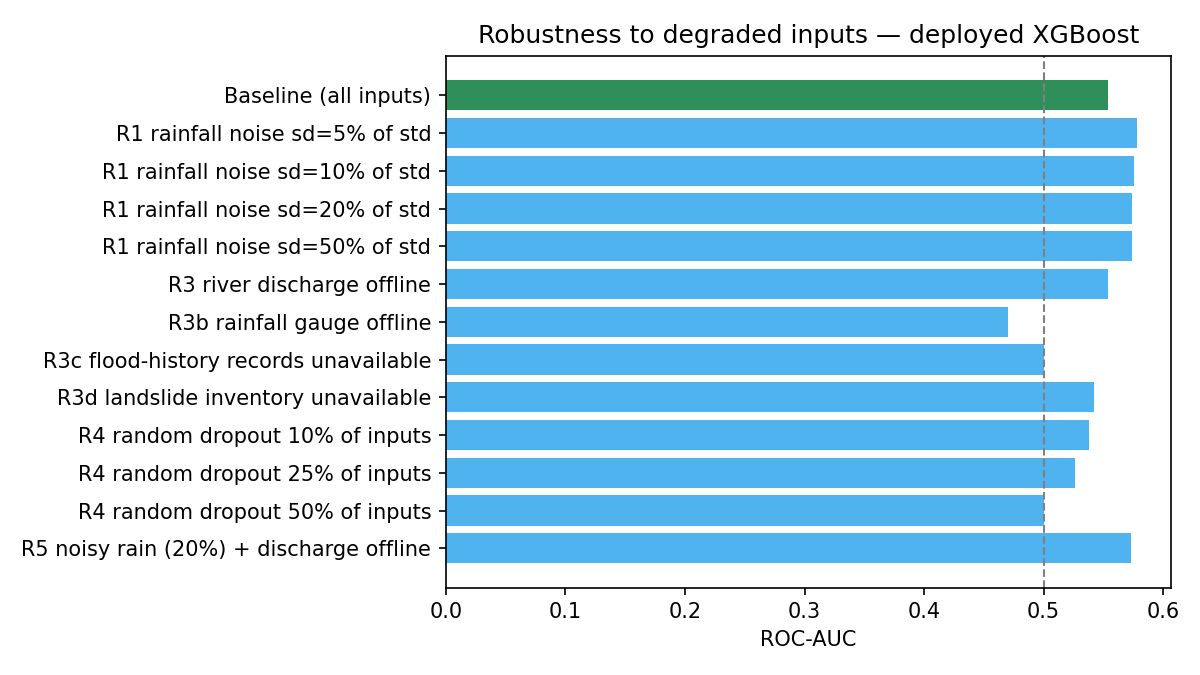

In [3]:
from src.robustness import run as rob_run
rob_run()
display(Image(filename='results/robustness/robustness_curves.png'))

## Industry-standard verification: POD · FAR · CSI · ETS · HSS (station-hour and district-day), BSS, reliability, honest lead time

In [4]:
from src.verification import run as ver_run
v = ver_run()
pd.DataFrame(v['contingency']).query("split == 'test' and level == '≥ ALERT'")[['unit','layer','events','POD','FAR','CSI','ETS','HSS','bias']]

        unit    level                         layer  events   POD   FAR   CSI    ETS    HSS   bias
station-hour  ≥ ALERT             hybrid (deployed)     624 0.314 0.944 0.050  0.034  0.065  5.590
station-hour  ≥ ALERT                       ML only     624 0.196 0.890 0.076  0.063  0.119  1.779
station-hour  ≥ ALERT            rainfall rule only     624 0.139 0.964 0.030  0.014  0.028  3.833
station-hour  ≥ ALERT           district prior only     624 1.000 0.981 0.019  0.000  0.000 52.482
station-hour ≥ SEVERE             hybrid (deployed)     624 0.191 0.947 0.043  0.028  0.055  3.585
station-hour ≥ SEVERE                       ML only     624 0.051 0.909 0.034  0.027  0.052  0.566
station-hour ≥ SEVERE            rainfall rule only     624 0.139 0.954 0.036  0.021  0.042  3.019
district-day  ≥ ALERT             hybrid (deployed)       8 0.750 0.974 0.026  0.014  0.028 28.625
district-day  ≥ ALERT                       ML only       8 0.375 0.940 0.055  0.044  0.084  6.250
district-d

,unit,layer,events,POD,FAR,CSI,ETS,HSS,bias
7,station-hour,hybrid (deployed),240,0.471,0.881,0.105,0.090,0.165,3.942
8,station-hour,ML only,240,0.275,0.918,0.068,0.053,0.100,3.342
9,station-hour,rainfall rule only,240,0.250,0.620,0.178,0.170,0.291,0.658
10,station-hour,district prior only,240,1.000,0.981,0.019,0.000,0.000,51.954
29,district-day,hybrid (deployed),4,0.750,0.939,0.060,0.046,0.089,12.250
30,district-day,ML only,4,0.250,0.960,0.036,0.023,0.045,6.250
31,district-day,rainfall rule only,4,0.750,0.897,0.100,0.087,0.160,7.250
32,district-day,district prior only,4,1.000,0.986,0.014,0.000,0.000,69.000
33,district-day,persistence (flood yesterday),4,0.000,1.000,0.000,-0.007,-0.015,1.000


## Precision · recall · F1 · MCC · ROC-AUC · PR-AUC (hour level, frozen thresholds)

In [5]:
from src.metrics_report import run as metrics_run
m = metrics_run()
pd.read_csv('results/metrics/metrics_summary.csv')

              model      split  precision  recall     f1    mcc  roc_auc  pr_auc  tp   fp  fn
logistic_regression validation     0.0799  0.2500 0.1211 0.1122   0.7644  0.0741  96 1106 288
logistic_regression       test     0.0765  0.3292 0.1241 0.1252   0.4512  0.0379  79  954 161
      random_forest validation     0.1555  0.0964 0.1190 0.1092   0.5624  0.0429  37  201 347
      random_forest       test     0.1468  0.1333 0.1397 0.1238   0.5954  0.0880  32  186 208
            xgboost validation     0.1153  0.2005 0.1464 0.1304   0.5657  0.0516  77  591 307
            xgboost       test     0.0605  0.1250 0.0815 0.0611   0.5345  0.0364  30  466 210


,model,split,threshold,rows,positives,precision,recall,f1,specificity,balanced_accuracy,mcc,roc_auc,pr_auc,brier,tp,fp,fn,tn,false_alarms_per_station_month,log_loss
0,logistic_regression,validation,0.45,20280,384,0.0799,0.2500,0.1211,0.9444,0.5972,0.1122,0.7644,0.0741,0.0523,96,1106,288,18790,31.60,0.3488
1,logistic_regression,test,0.45,12469,240,0.0765,0.3292,0.1241,0.9220,0.6256,0.1252,0.4512,0.0379,0.0713,79,954,161,11275,32.90,0.5893
2,random_forest,validation,0.05,20280,384,0.1555,0.0964,0.1190,0.9899,0.5431,0.1092,0.5624,0.0429,0.0187,37,201,347,19695,5.74,0.5556
3,random_forest,test,0.05,12469,240,0.1468,0.1333,0.1397,0.9848,0.5591,0.1238,0.5954,0.0880,0.0185,32,186,208,12043,6.41,0.5120
4,xgboost,validation,0.70,20280,384,0.1153,0.2005,0.1464,0.9703,0.5854,0.1304,0.5657,0.0516,0.0632,77,591,307,19305,16.89,0.2708
5,xgboost,test,0.70,12469,240,0.0605,0.1250,0.0815,0.9619,0.5434,0.0611,0.5345,0.0364,0.0683,30,466,210,11763,16.07,0.2822


In [6]:
from src.phase4_report import run as report_run
report_run()
display(Markdown(Path('results/phase4_report.md').read_text(encoding='utf-8')[:6000]))

wrote results/phase4_report.md and ['calibration_scores.csv', 'feature_columns.json', 'warning_thresholds.json', 'xgboost_model.joblib']


# Phase 4 Report — Uncertainty-Aware and Robust Flash-Flood Prediction

## 0. Corrections made before Phase 4
- **Duplicate station-hours** (one gauge with two coordinate pairs fanned out the merge) fixed → 21,464 rows.
- **Label coverage**: the IMD flood inventory ends 2023-08-26. Rows after that were silently labelled 0; they are now
  *unlabelled* (used for replay only). Labelled data: 7,830 rows, 44 positives, 6 flood episodes.
- **Location leakage**: raw latitude/longitude carried 38 % of gain. Final model = `Exp_G_Static_History` (no coordinates).

## 1. Evaluation protocol — leave-one-event-out CV (src/event_cv.py)
Each flood episode (±3 days) is held out in turn; training excludes a 7-day buffer around it.

| experiment                               |   features |   folds |   rows |   positives |   pooled_roc_auc |   pooled_pr_auc |   base_rate |   mean_fold_roc_auc |   min_fold_roc_auc |
|:-----------------------------------------|-----------:|--------:|-------:|------------:|-----------------:|----------------:|------------:|--------------------:|-------------------:|
| Exp_A_Rainfall_Only                      |         10 |       6 |  15035 |         730 |           0.5647 |          0.057  |      0.0486 |              0.6075 |             0.4233 |
| Exp_B_Rainfall_Discharge                 |         14 |       6 |  15035 |         730 |           0.5911 |          0.1131 |      0.0486 |              0.6879 |             0.5655 |
| Exp_C_Rainfall_Discharge_FloodHist       |         21 |       6 |  15035 |         730 |           0.7463 |          0.2124 |      0.0486 |              0.7856 |             0.5679 |
| Exp_D_Rainfall_Discharge_Flood_Landslide |         25 |       6 |  15035 |         730 |           0.7459 |          0.2055 |      0.0486 |              0.7861 |             0.5679 |
| Exp_E_Full_Multimodal                    |         32 |       6 |  15035 |         730 |           0.7362 |          0.2546 |      0.0486 |              0.841  |             0.55   |
| Exp_F_No_Location                        |         30 |       6 |  15035 |         730 |           0.7364 |          0.2545 |      0.0486 |              0.8398 |             0.5429 |
| Exp_G_Static_History                     |         23 |       6 |  15035 |         730 |           0.8583 |          0.196  |      0.0486 |              0.8619 |             0.8083 |
| Exp_H_Multisource                        |         42 |       6 |  15035 |         730 |           0.8245 |          0.1357 |      0.0486 |              0.7796 |             0.4985 |
| Exp_T_Trigger_Only                       |         29 |       6 |  15035 |         730 |           0.4784 |          0.0866 |      0.0486 |              0.6192 |             0.3148 |

Single chronological split (train 2022 · val Jan–Jul 2023 · test Aug 2023, 17 positives) for reference:

| model               | feature_set          |   threshold |   val_roc_auc |   val_pr_auc |   test_roc_auc |   test_pr_auc |   test_recall |
|:--------------------|:---------------------|------------:|--------------:|-------------:|---------------:|--------------:|--------------:|
| Logistic Regression | Exp_G_Static_History |        0.45 |        0.7644 |       0.0741 |         0.4512 |        0.0379 |        0.3292 |
| Random Forest       | Exp_G_Static_History |        0.05 |        0.5624 |       0.0429 |         0.5954 |        0.088  |        0.1333 |
| XGBoost             | Exp_G_Static_History |        0.7  |        0.5657 |       0.0516 |         0.5345 |        0.0364 |        0.125  |

## 2. Uncertainty — Venn-Abers + Mondrian conformal (src/conformal.py)
Calibration on 20,280 validation rows (384 floods); test 12469 rows (240 floods).
Brier score 0.06832 (raw) → 0.01907 (calibrated).

|   nominal |   coverage_all |   coverage_flood |   coverage_no_flood |   share_uncertain |   share_flood_singleton |
|----------:|---------------:|-----------------:|--------------------:|------------------:|------------------------:|
|      0.8  |         0.9386 |            0.875 |              0.9398 |            0.9081 |                  0.0643 |
|      0.9  |         0.9386 |            0.875 |              0.9398 |            0.9081 |                  0.0643 |
|      0.95 |         0.9602 |            0.875 |              0.9619 |            0.9326 |                  0.0398 |

Nominal coverage is met for both classes at 90 % and 95 %. Most sets are "uncertain": the model rarely separates
the classes with confidence, which is the honest outcome with ~20 calibration floods.

## 3. Explanations — SHAP (src/explain.py)
| feature                           |   mean_abs_shap |
|:----------------------------------|----------------:|
| district_mean_flood_duration_days |      0.985937   |
| rain_48h                          |      0.22995    |
| district_flood_severity_index     |      0.211586   |
| dist_to_nearest_landslide_km      |      0.127755   |
| api_decay_85                      |      0.0417421  |
| rain_max_intensity_24h            |      0.0346539  |
| rain_72h                          |      0.0337078  |
| landslide_count_10km              |      0.0170388  |
| rain_24h                          |      0.0150324  |
| rain_12h                          |      0.00248775 |

## 4. Warning levels (src/warning_levels.py)
Calibrated-probability cut-offs {'WATCH': 0.03787, 'ALERT': 0.09467, 'SEVERE': 0.18935, 'EXTREME': 0.3787} (base rate 1.89%); a conformal FLOOD set lifts to ≥ ALERT.

| split      | layer     | tier    |   rows |   flood_rows |   hit_rate |   lift_vs_base |
|:-----------|:----------|:--------|-------:|-------------:|-----------:|---------------:|
| validation | tier_ml   | NORMAL  |  19603 |          307 |     0.0157 |           0.83 |
| validation | tier_ml   | WATCH   |    369 |           21 |     0.0569 |           3.01 |
| validation | tier_ml   | ALERT   |    143 |           38 |     0.2657 |          14.03 |
| validation | tier_ml   | SEVERE  |    165 |     